# Progetto Machine Learning: *Letter Recognition*



## Dataset utilizzato:

Al fine di analizzare due modelli di apprendimento supervisionato, abbiamo scelto di utilizzare un dataset contenente feature numeriche relative a immagini di lettere maiuscole latine scritte a mano.

Le feature sono degli interi normalizzati tra 0 e 16, corrispondenti ad attributi dell'immagine campione come:
- Totale dei pixel ON (accesi)
- Media dei pixel ON sull'asse delle ordinate
- Media dei pixel ON sull'asse delle ascisse
- Altezza e larghezza del box di scrittura

...e altre ancora.
La variabile target è di tipo categorico, e corrisponde alla lettera caratterizzante (e.g. A, E, P, ...)
Il dataset ha numerosità pari a 20.000; ha una shape di [20000, 16].

Il dataset è consultabile [a questo link](https://archive.ics.uci.edu/dataset/59/letter+recognition).


## Modelli utilizzati:

Fra i modelli visti a lezione, abbiamo scelto di utilizzarne due che seguono un approccio supervisionato, in quanto data l'eterogeneità del dataset e il numero relativamente alto di classi da cui è caratterizzata, non abbiamo ritenuto valido un approccio non supervisionato come k-means.

Abbiamo perciò scelto le **Reti neurali** e le **Support Vector Machine**, scartando l'approccio Naive Bayes in quanto, essendo le feature numeriche di un'immagine fortemente dipendenti fra loro, non sarebbe stato il più proficuo, e scartando anche gli alberi di decisione data la numerosità del dataset e la numerosità delle classi, oltre che il rischio di andare in overfitting, o in underfitting nel caso in cui avessimo deciso di limitare la profondità dell'albero.

In generale, abbiamo ritenuto che i modelli da noi scelti fossero più performanti in termini di accuracy, e più interessanti da un punto di vista tendenziale.
<br>
<br>

# Librerie utilizzate

Le librerie che abbiamo utilizzato sono un sottoinsieme delle librerie viste durante i laboratori. In particolare:
- *Keras*: libreria per l'addestramento di reti neurali, che fornisce skeletons di modelli(come Sequential e Dense)

- *Matplotplot*: per la visualizzazione dei dati con grafici

- *Pandas*: per la definizione di dataframe, per importare il dataset

- *SKLearn*: per l'induzione delle SVM, per la separazione del dataset, per il GridSearch

<br>
<br>










In [ ]:
from keras.utils import to_categorical
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
import numpy as np
from sklearn.model_selection import GridSearchCV



## **Elaborazione dei dati e importazione del dataset**

Iniziamo con l'importare i dati da file CSV all'interno di un DataFrame grazie all'ausilio della libreria Pandas.

In [ ]:
from google.colab import drive
import pandas as pd

drive.mount('/content/drive/')

df = pd.read_csv ("drive/MyDrive/Letter Recognition (Progetto ML)/letter-recognition.csv")
print(df.shape)
print(df.head())
x = df.drop(columns="letter",axis=1)


Drive already mounted at /content/drive/; to attempt to forcibly remount, call drive.mount("/content/drive/", force_remount=True).
(20000, 17)
  letter  xbox  ybox  width  height  onpix  xbar  ybar  x2bar  y2bar  xybar  \
0      T     2     8      3       5      1     8    13      0      6      6   
1      I     5    12      3       7      2    10     5      5      4     13   
2      D     4    11      6       8      6    10     6      2      6     10   
3      N     7    11      6       6      3     5     9      4      6      4   
4      G     2     1      3       1      1     8     6      6      6      6   

   x2ybar  xy2bar  xedge  xedgey  yedge  yedgex  
0      10       8      0       8      0       8  
1       3       9      2       8      4      10  
2       3       7      3       7      3       9  
3       4      10      6      10      2       8  
4       5       9      1       7      5      10  



Estraiamo la colonna target dal DataFrame del dataset, e codifichiamo ogni etichetta (A, B, C, ...) con un intero normalizzato tra 0 e 25 mediante la funzione `fit_transform`. Facciamo questa operazione perché le reti neurali lavorano solo con dati numerici.

Successivamente, mediante la funzione `to_categorical` della libreria Keras, andiamo a ricodificare le label, trasformate adesso in un intero, in One Hot Encoding. Questo ci consentirà di sfruttare una particolare funzione di loss (categorical_crossentropy).

In [ ]:
from sklearn.preprocessing import LabelEncoder

y_orig = df["letter"]
l = LabelEncoder()
y = l.fit_transform(y_orig)
print("Target Label Encoded: \n", y)
y = to_categorical(y)
print("Target One Hot Encoded: \n", y)

Target Label Encoded: 
 [19  8  3 ... 19 18  0]
Target One Hot Encoded: 
 [[0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 ...
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 [1. 0. 0. ... 0. 0. 0.]]


Procediamo con la suddivisione del dataset in due partizioni di dati: training set (80%) e test set (20%).
Sfruttiamo la funzione `train_test_split` di sklearn.


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    x, #Intero dataset senza la colonna target
    y, #Colonna target codificata in One-Hot-Encoding
    test_size=0.2,
    shuffle=True,
    random_state=42
)

# **Architettura della NN**

La nostra rete neurale è composta da 4 layer densi di dimensione (16, 256, 128, 26); lo strato di input ha numerosità equivalente allo spazio delle feature, lo strato di output risulta essere di dimensione pari al numero di lettere maiuscole appartenenti al nostro alfabeto e infine le dimensioni degli strati nascosti sono state ottenute testando vari parametri (range 40-500), abbiamo riscontrato che i valori 256 e 128 fornivano il miglior rapporto fra prestazioni computazionali e accuratezza finale del modello.<br>
Le funzioni di attivazione nei vari strati sono ReLU e Softmax; la prima per gli strati di input e hidden mentre la seconda per lo strato di output. La decisione di utilizzare Softmax è dovuta al tipo di classificazione richiesta dal problema quindi una classificazione multiclasse con singola uscita.

In [ ]:
from keras.src.layers import Dense
from keras.src.models import Sequential

model = Sequential()
model.add(Dense(256, input_shape=(16, ), activation='relu'))
model.add(Dense(128, activation='relu'))
model.add(Dense(26, activation='softmax'))

/home/matteo/.local/lib/python3.12/site-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
2025-02-24 16:08:56.719223: E external/local_xla/xla/stream_executor/cuda/cuda_driver.cc:152] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Una volta definita l'architettura, procediamo col compilare il modello e ad addestrarlo.
La scelta dei parametri per l'addestramento è giustificata di seguito.

In [ ]:
from keras.optimizers import Adam
import time
model.compile(
    loss='categorical_crossentropy',
    optimizer=Adam(learning_rate=8e-5),
    metrics=['accuracy']
)

initial_weights = model.get_weights()
start = time.time()
history = model.fit(
    X_train,
    y_train,
    epochs=150,
    batch_size=32,
    verbose=1
)
end = time.time()
print("Training time: ", end - start)

Epoch 1/150
500/500 ━━━━━━━━━━━━━━━━━━━━ 1s 800us/step - accuracy: 0.1795 - loss: 3.1684
Epoch 2/150
500/500 ━━━━━━━━━━━━━━━━━━━━ 0s 779us/step - accuracy: 0.5693 - loss: 1.8241
Epoch 3/150
500/500 ━━━━━━━━━━━━━━━━━━━━ 0s 798us/step - accuracy: 0.6660 - loss: 1.4022
Epoch 4/150
500/500 ━━━━━━━━━━━━━━━━━━━━ 0s 775us/step - accuracy: 0.7168 - loss: 1.1745
Epoch 5/150
500/500 ━━━━━━━━━━━━━━━━━━━━ 0s 771us/step - accuracy: 0.7409 - loss: 1.0515
Epoch 6/150
500/500 ━━━━━━━━━━━━━━━━━━━━ 0s 793us/step - accuracy: 0.7567 - loss: 0.9744
Epoch 7/150
500/500 ━━━━━━━━━━━━━━━━━━━━ 0s 788us/step - accuracy: 0.7685 - loss: 0.9095
Epoch 8/150
500/500 ━━━━━━━━━━━━━━━━━━━━ 0s 771us/step - accuracy: 0.7798 - loss: 0.8557
Epoch 9/150
500/500 ━━━━━━━━━━━━━━━━━━━━ 0s 769us/step - accuracy: 0.7866 - loss: 0.8108
Epoch 10/150
500/500 ━━━━━━━━━━━━━━━━━━━━ 0s 800us/step - accuracy: 0.7917 - loss: 0.7889
Epoch 11/150
500/500 ━━━━━━━━━━━━━━━━━━━━ 0s 752us/step - accuracy: 0.8006 - loss: 0.7593
Epoch 12/150
500/50

Abbiamo deciso di utilizzare una loss di tipo `categorical_crossentropy`, data la natura del problema.
Abbiamo ritenuto opportuno studiare il learning rate ottimale da utilizzarsi con Adam, studiando la curva loss/epoche dei vari esperimenti, facendo variare il learning rate di un valore pari a 1e-4 di volta in volta. Così facendo, abbiamo anche determinato il numero di epoche.

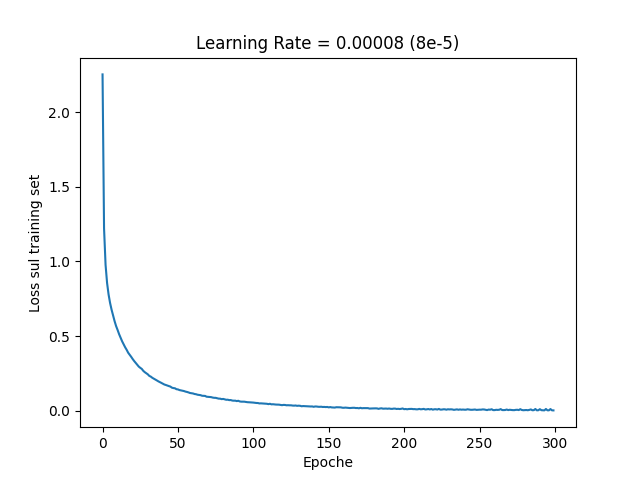

Come si può notare dal grafico, ottenuto addestrando il modello per 300 epoche, notiamo una convergenza al raggiungimento delle 150 epoche. Continuando ad addestrare si raggiunge senz'altro un valore della loss minore sui dati di training, andando tuttavia incontro ad un forte **overfitting**.

Al termine dell'addestramento del modello, eseguiamo un analisi preliminare e puramente indicativa sul test set, determinando accuracy e loss.



In [ ]:
loss, accuracy = model.evaluate(X_test, y_test, verbose=1, batch_size=16)

print("Loss sui dati di test: ", loss)
print("Accuracy sui dati di test: ", accuracy)

250/250 ━━━━━━━━━━━━━━━━━━━━ 0s 635us/step - accuracy: 0.9460 - loss: 0.1726
Loss sui dati di test:  0.16756047308444977
Accuracy sui dati di test:  0.9482499957084656



Come possiamo notare, raggiungiamo un valore di accuracy sui dati di test del 95%, il chè ci indica bontà del modello, nonostante sia in leggero overfitting.
La loss media si attesta sul 16% - il modello assegna una probabilità $p = e^{-0.16} = 0.86 $ circa alla label corretta.



# **Validazione del modello**

Tramite una valutazione sui dati di test, abbiamo appurato che il modello, nonostante un leggero overfitting, riesce a generalizzare bene sui 4000 esempi (il 20% del dataset) forniti.

Sfruttiamo la tecnica di validazione **K-Fold** con k = 5 per appurare la bontà del modello, e garantire una buona generalizzazione.





In [ ]:
from sklearn.model_selection import KFold
from keras.callbacks import EarlyStopping
import scipy.stats as st
k = 5
folds = KFold(n_splits=k, shuffle=True, random_state=42)
folds.split(x, y)
accuracy_k_fold = []


for i, (train_index, valid_index) in enumerate(folds.split(x, y)):
        X_train, X_valid = x.iloc[train_index], x.iloc[valid_index]
        y_train, y_valid = y[train_index], y[valid_index]

        model.set_weights(initial_weights)
        history = model.fit(
            X_train,
            y_train,
            validation_data=(X_valid, y_valid),
            epochs=150,
            batch_size=32,
            verbose=1,
            callbacks=[EarlyStopping(patience = 3)]
        )
        y_pred_valid = model.predict(X_valid)
        accuracy_k_fold.append(history.history['val_accuracy'][-1])


confint = st.t.interval(
    confidence=0.90,
    df=len(accuracy_k_fold) - 1,
    loc=np.mean(accuracy_k_fold),
    scale=st.sem(accuracy_k_fold)
)

print("Intervallo di confidenza = [", float(confint[0]), ", ", float(confint[1]), "]")
print("Accuracy ottenuta ad ogni iterazione", accuracy_k_fold)

Epoch 1/150
500/500 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.2287 - loss: 2.9529 - val_accuracy: 0.5400 - val_loss: 1.9479
Epoch 2/150
500/500 ━━━━━━━━━━━━━━━━━━━━ 0s 924us/step - accuracy: 0.5772 - loss: 1.7942 - val_accuracy: 0.6440 - val_loss: 1.4857
Epoch 3/150
500/500 ━━━━━━━━━━━━━━━━━━━━ 0s 977us/step - accuracy: 0.6553 - loss: 1.4323 - val_accuracy: 0.6883 - val_loss: 1.2699
Epoch 4/150
500/500 ━━━━━━━━━━━━━━━━━━━━ 1s 988us/step - accuracy: 0.6990 - loss: 1.2386 - val_accuracy: 0.7210 - val_loss: 1.1277
Epoch 5/150
500/500 ━━━━━━━━━━━━━━━━━━━━ 1s 988us/step - accuracy: 0.7291 - loss: 1.1019 - val_accuracy: 0.7465 - val_loss: 1.0374
Epoch 6/150
500/500 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.7495 - loss: 1.0087 - val_accuracy: 0.7552 - val_loss: 0.9688
Epoch 7/150
500/500 ━━━━━━━━━━━━━━━━━━━━ 0s 961us/step - accuracy: 0.7588 - loss: 0.9575 - val_accuracy: 0.7673 - val_loss: 0.9137
Epoch 8/150
500/500 ━━━━━━━━━━━━━━━━━━━━ 1s 987us/step - accuracy: 0.7689 - loss: 0.902

Otteniamo un intervallo di confidenza molto stretto e alto: il modello promette ottime prestazioni

## **Matrice di confusione**

Definiamo alcune funzioni di utility

In [ ]:
def ohe_to_label(nparr):
    for i in range(len(nparr)):
        if nparr[i] == 1:
            return i

def alphabet():
    l26 = list(range(26))
    for i in range(len(l26)):
        l26[i] = chr(65 + i)
    return l26

def scale(e):
    return e / 256


Stampiamo la matrice di confusione delle predizioni del nuovo modello (addestrato con Cross Validation) sui dati di test iniziali - vale a dire il 20% del dataset.



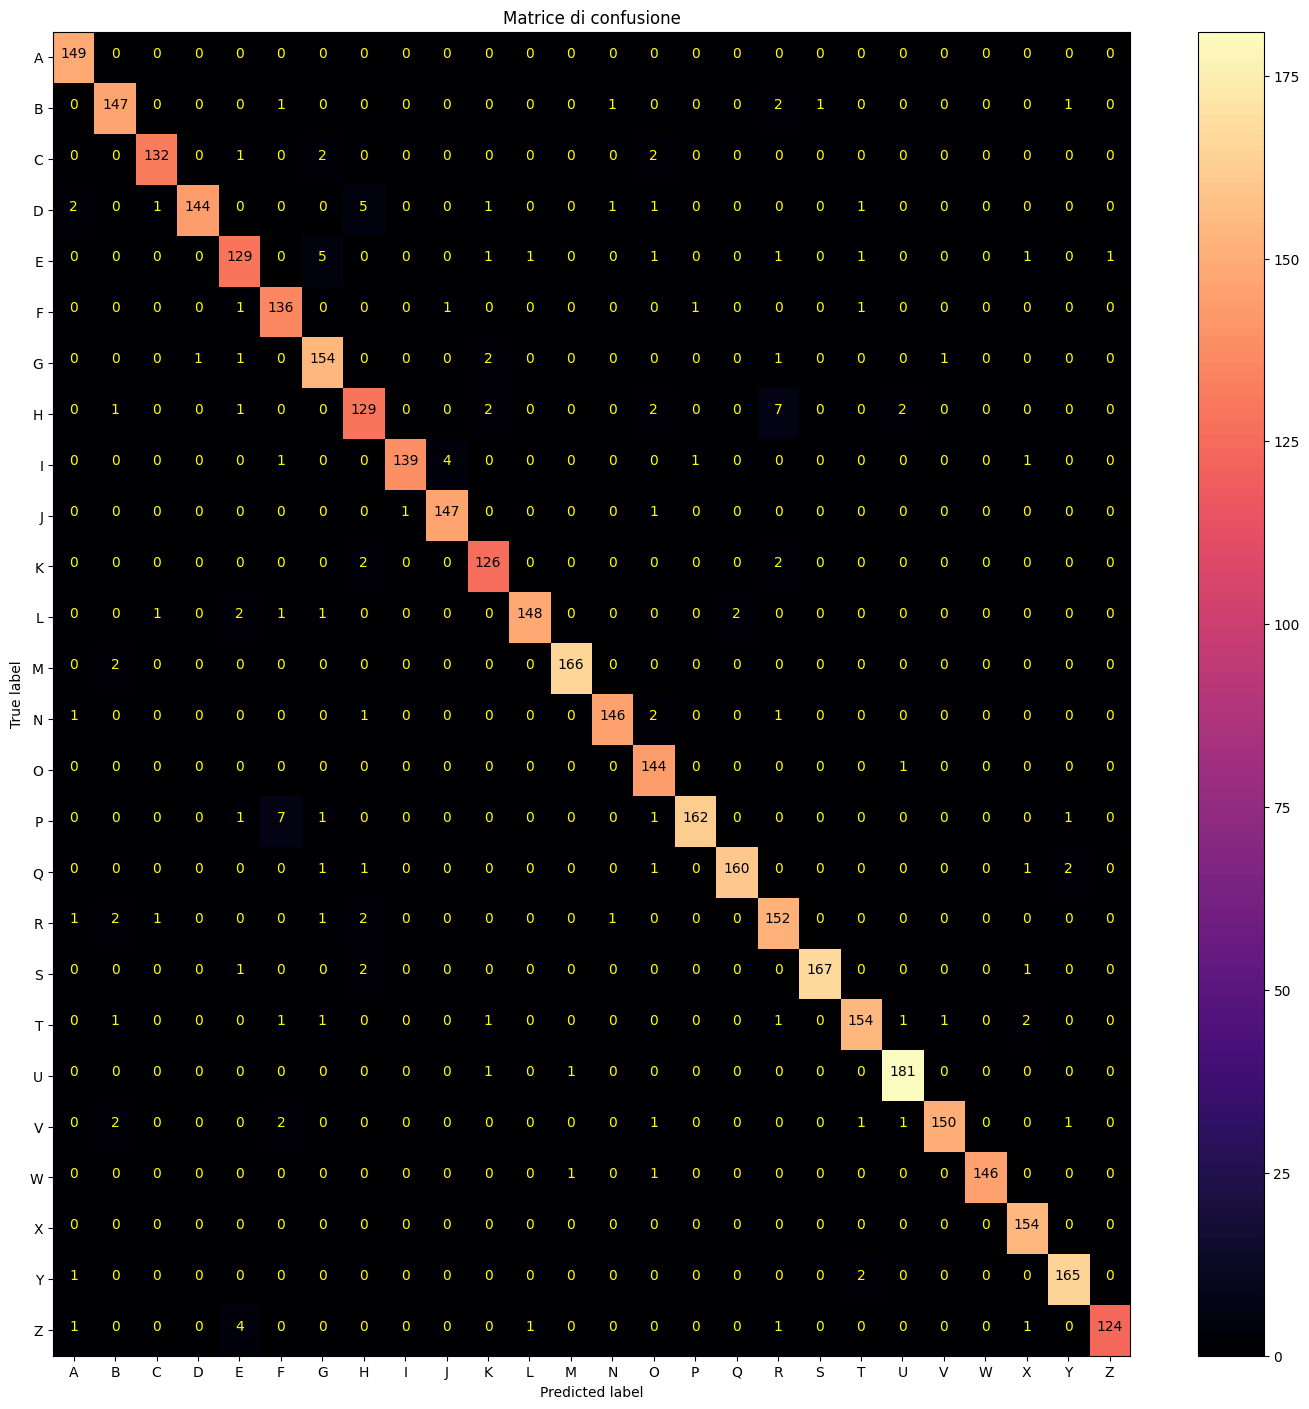

In [ ]:
import itertools
from sklearn.metrics import confusion_matrix

ytt = np.array(list(map(ohe_to_label, y_test)))
y_pred_test_prob = model.predict(X_test, verbose = 0)
y_pred_test = np.argmax(y_pred_test_prob, axis=1)

cm = confusion_matrix(ytt, y_pred_test) #provare con labels parameter

plt.figure(figsize = (14,14))
plt.imshow(
    cm,
    interpolation='nearest',
    aspect='auto',
    cmap=plt.cm.magma
)
plt.title("Matrice di confusione")
plt.colorbar()
tick_marks = np.arange(26)

plt.xticks(tick_marks, alphabet())
plt.yticks(tick_marks, alphabet())

thresh = cm.max() / 2.
for i, j in itertools.product(range(cm.shape[0]), range(cm.shape[1])):
    plt.text(j, i, cm[i, j],
            horizontalalignment="center",
            color="black" if cm[i, j] > thresh else "yellow")

plt.tight_layout()
plt.ylabel('True label')
plt.xlabel('Predicted label')
plt.savefig("plots/Plot_Conf_Mat.png")


Curva ROC:


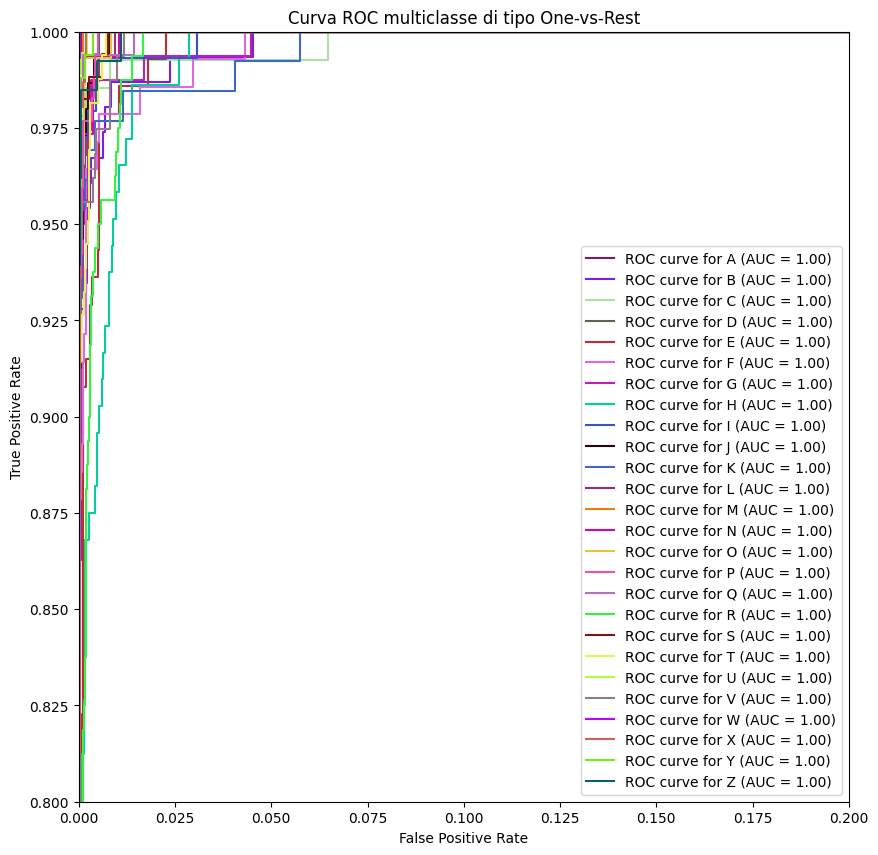

In [ ]:
from sklearn.metrics import RocCurveDisplay

fig, ax = plt.subplots(figsize=(10, 10))
colors = []
for i in range(26):
    t = np.random.choice(range(256), size=3)
    t = map(int, t)
    t = map(scale, t)
    colors.append(tuple(t))
for class_id, color in zip(range(26), colors):
    RocCurveDisplay.from_predictions(
        y_test[:, class_id],
        y_pred_test_prob[:, class_id],
        name=f"ROC curve for {alphabet()[class_id]}",
        color=color,
        ax=ax,
        despine=False,
    )

_ = ax.set(
    xlim=(0, 0.2),
    ylim=(0.8, 1),
    xlabel="False Positive Rate",
    ylabel="True Positive Rate",
    title="Curva ROC multiclasse di tipo One-vs-Rest",
)

Stampiamo infine Precision, Recall e F-Score

In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score

precision = precision_score(ytt, y_pred_test, average='weighted')
recall = recall_score(ytt, y_pred_test, average='weighted')
f1 = f1_score(ytt, y_pred_test, average='weighted')

print("Precision: ", precision)
print("Recall: ", recall)
print("F1: ", f1)

Precision:  0.9635534137617314
Recall:  0.96275
F1:  0.9628180075728195


<br>
<br>




# **Support Vector Machine**

Avendo già definito il DataFrame degli esempi del dataset e avendo già estratto la colonna target, ci accingiamo ad addestrare la nostra SVM. Infatti, questo modello non ha bisogno che le varie etichette siano One Hot Encoded, per cui la rappresentazione nativa del dataset, ci consente di non effettuare ulteriori trasformazioni.
<br>
<br>
Suddividiamo quindi il dataset, proprio come nelle reti neurali, in Training Set e Test Set.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    x,
    y_orig,
    test_size=0.2,
    shuffle=True,
    random_state=42
)



Proviamo ad addestrare una semplice SVM con kernel lineare per poter evidenziare le caratteristiche di questo kernel (lineare), e per poterlo poi confrontare con altri tipi di kernel.

In [ ]:
from sklearn import svm
from sklearn.metrics import accuracy_score

SVM_naive = svm.SVC(
    kernel='linear',
    random_state=42,
    probability=True #Per poter plottare in seguito il grafico della curva ROC
)

SVM_naive.fit(X_train, y_train)

svm_pred = SVM_naive.predict(X_test)
svm_accuracy = accuracy_score(y_test, svm_pred)

print("Accuracy: ", svm_accuracy)

Accuracy:  0.8545



Riusciamo ad ottenere un'accuratezza dell'85% senza toccare alcun parametro della SVM, e impostando il valore di C, ossia il parametro di regolarizzazione, ad 1.0 (valore di default) e utilizzando un kernel lineare.


Possiamo migliorare le prestazioni del modello andando a modificare il kernel, utilizzandone uno più robusto, soprattutto nel nostro caso in cui abbiamo a che fare con tante feature.

Sfruttiamo l'approccio di GridSearch per effettuare una ricerca subottimale dei parametri di addestramento, escludendo ora l'utilizzo del kernel lineare.

GridSearch andrà ad effettuare $n$ addestramenti con:<br><br> $n = opzioni\_kernel * |C\_vec| * |gamma\_vec|$
<br><br>
con:
- C_vec: vettore in cui sono contenuti 20 valori possibili di regolarizzazione;
- gamma_vec: vettore in cui sono contenuti i coefficienti del kernel (vale per `rbf` e `poly`)



In [ ]:
start_val = 0.1
c_vec = [start_val]
for i in range(20):
    c_vec.append(c_vec[-1] * 1.5)


grid = {
    'kernel': ['rbf', 'poly'],
    'C': c_vec,
    'gamma' : [0.1, 1, 10]
}

gscv = GridSearchCV(
    SVM_naive,
    grid,
    scoring='accuracy',
    cv=5,
    verbose=10
)
start = time.time()
gscv.fit(X_train, y_train)
end = time.time()
print("Elapsed time: ", end - start)
print("Best params = ", gscv.best_params_)


Fitting 5 folds for each of 126 candidates, totalling 630 fits
[CV 1/5; 1/126] START C=0.1, gamma=0.1, kernel=rbf..............................
[CV 1/5; 1/126] END C=0.1, gamma=0.1, kernel=rbf;, score=0.855 total time=   6.6s
[CV 2/5; 1/126] START C=0.1, gamma=0.1, kernel=rbf..............................
[CV 2/5; 1/126] END C=0.1, gamma=0.1, kernel=rbf;, score=0.864 total time=   6.4s
[CV 3/5; 1/126] START C=0.1, gamma=0.1, kernel=rbf..............................
[CV 3/5; 1/126] END C=0.1, gamma=0.1, kernel=rbf;, score=0.877 total time=   6.3s
[CV 4/5; 1/126] START C=0.1, gamma=0.1, kernel=rbf..............................
[CV 4/5; 1/126] END C=0.1, gamma=0.1, kernel=rbf;, score=0.863 total time=   6.5s
[CV 5/5; 1/126] START C=0.1, gamma=0.1, kernel=rbf..............................
[CV 5/5; 1/126] END C=0.1, gamma=0.1, kernel=rbf;, score=0.862 total time=   6.3s
[CV 1/5; 2/126] START C=0.1, gamma=0.1, kernel=poly.............................
[CV 1/5; 2/126] END C=0.1, gamma=0.1, ker

Definiamo quindi il nostro $C\_vec$ come una lista di 20 parametri possibili per C in cui <br>$C\_vec[i] = C\_vec[i - 1] * 1,5$, con $C\_vec[0] = 0.1$

Definiamo $gamma\_vec = [0.1, 1, 10]$, anche per non innalzare troppo la complessità computazionale della search.

Proviamo quindi a determinare la funzione kernel più adeguata per la tipologia di problema che stiamo affrontando.
Al termine della Grid Search, l'interprete stampa i parametri subottimali:

- **Kernel** : rbf
- **C** : 12.974
- **gamma** : 0.1


Otteniamo una accuracy pari a:

In [ ]:
gscv.score(X_test, y_test)

0.974

Il che ci indica che il modello riesce bene a generalizzare, classificando correttamente, nel 97% dei casi, istanze mai viste prima.

Calcoliamo adesso gli indici di performance del modello:


In [ ]:
y_pred = gscv.predict(X_test)
fscore_SVM = f1_score(y_test, y_pred, average='weighted')
precision_SVM = precision_score(y_test, y_pred, average='weighted')
recall_SVM = recall_score(y_test, y_pred, average='weighted')

print("F-Score: ", fscore_SVM)
print("Precision: ", precision_SVM)
print("Recall: ", recall_SVM)

F-Score:  0.9740143341093603
Precision:  0.9743765586862595
Recall:  0.974


Stampiamo ora la matrice di confusione

Text(0.5, 124.72222222222219, 'Predicted label')

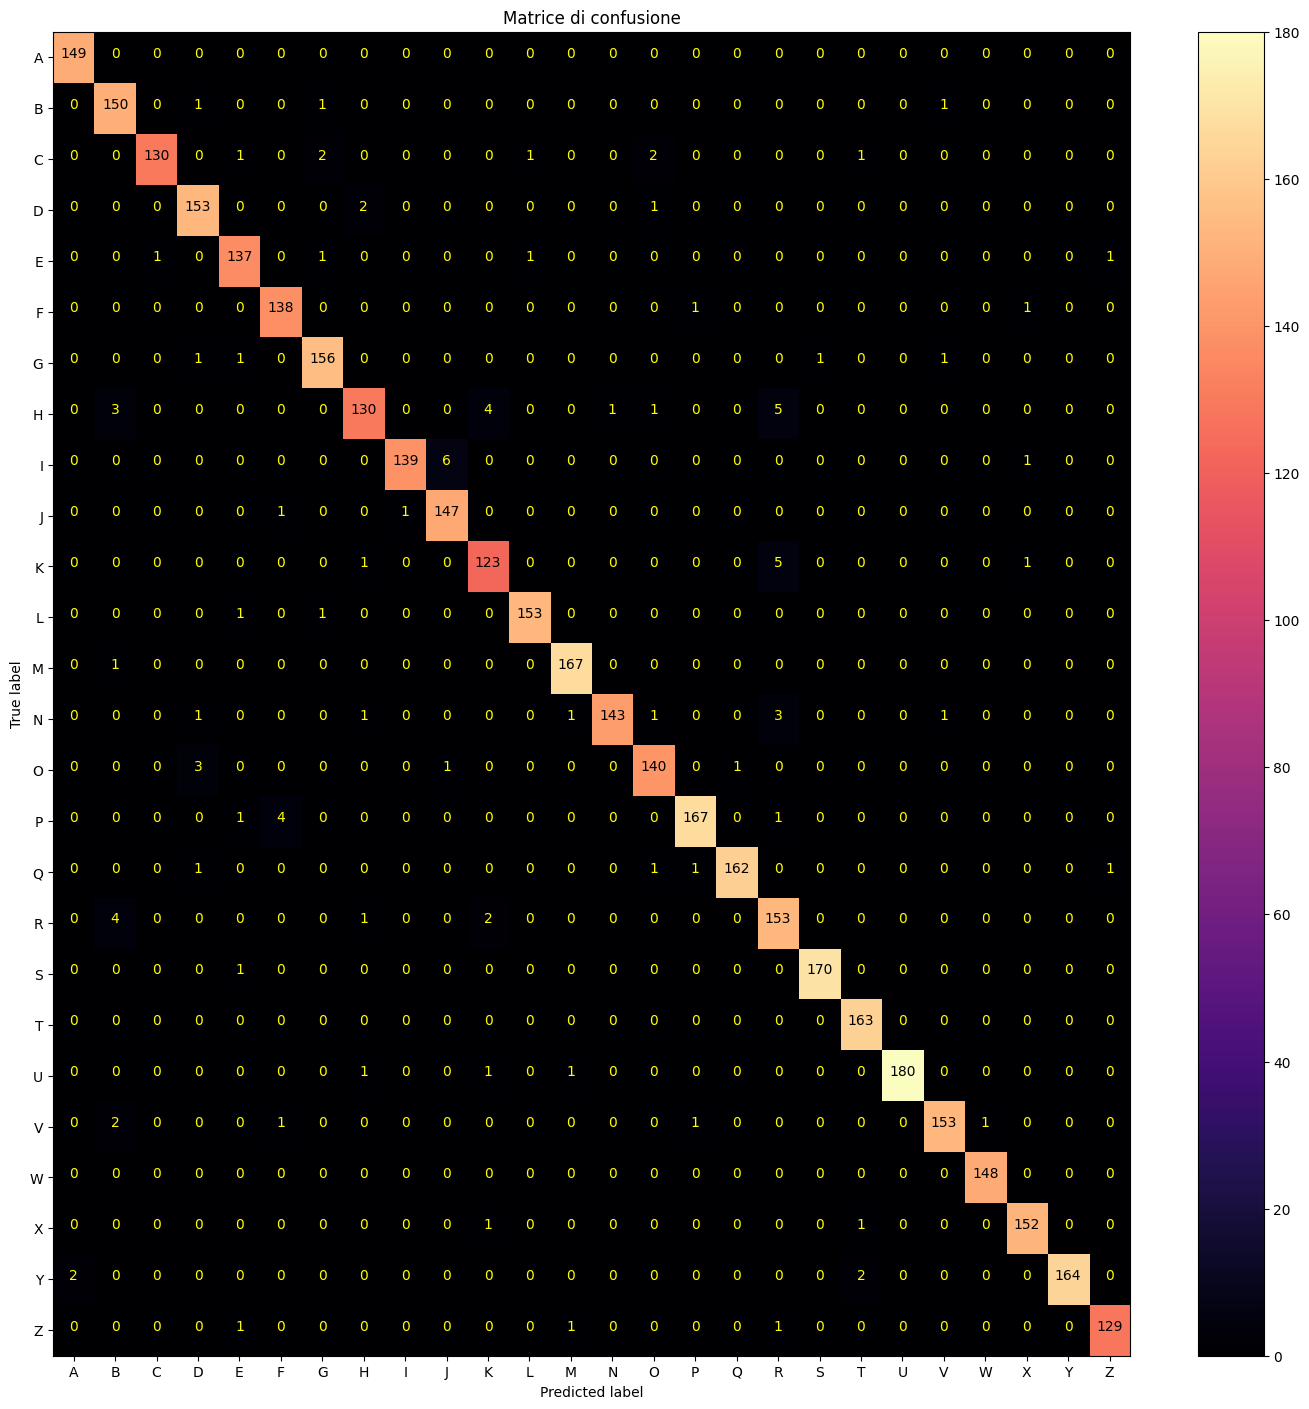

In [ ]:

cm_svm = confusion_matrix(y_test, y_pred)

plt.figure(figsize = (14,14))
plt.imshow(
    cm_svm,
    interpolation='nearest',
    aspect='auto',
    cmap=plt.cm.magma
)
plt.title("Matrice di confusione")
plt.colorbar()
tick_marks = np.arange(26)

plt.xticks(tick_marks, alphabet())
plt.yticks(tick_marks, alphabet())

thresh = cm_svm.max() / 2.
for i, j in itertools.product(range(cm_svm.shape[0]), range(cm_svm.shape[1])):
    plt.text(j, i, cm_svm[i, j],
            horizontalalignment="center",
            color="black" if cm_svm[i, j] > thresh else "yellow")

plt.tight_layout()
plt.ylabel('True label')
plt.xlabel('Predicted label')

Notiamo una certa somiglianza con la matrice di confusione della rete neurale, a meno di qualche esempio in più classificato correttamente dalla Support Vector Machine.



Curva ROC:



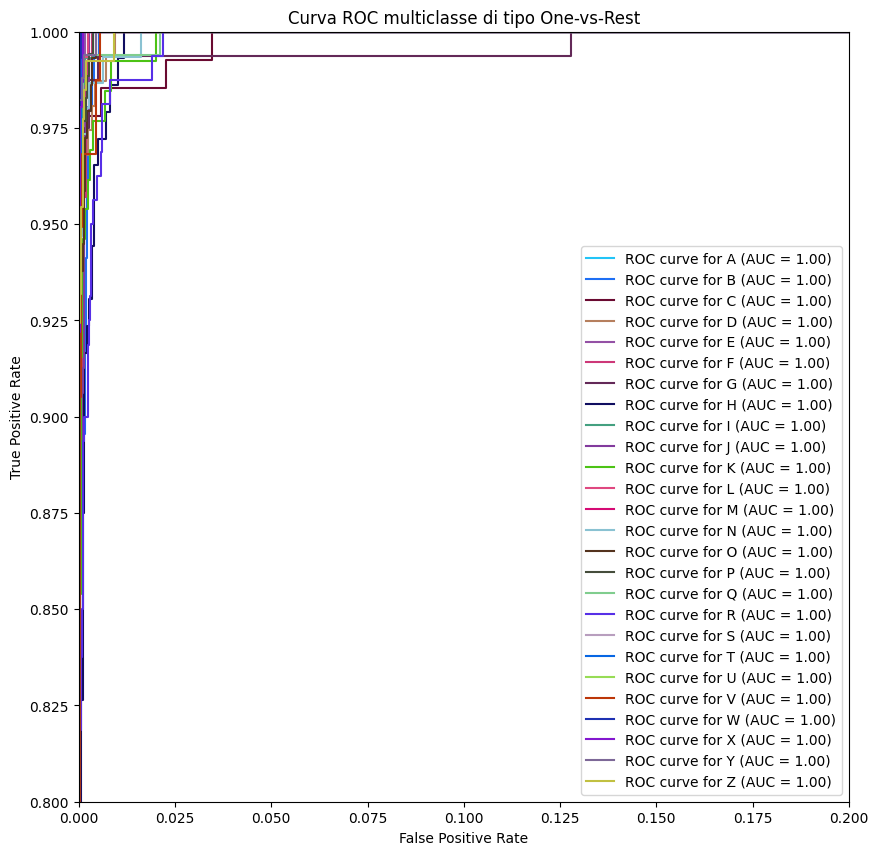

In [ ]:
y_pred_SVM = gscv.predict_proba(X_test)

y_test_OHE = LabelEncoder().fit_transform(y_test)
y_test_OHE = to_categorical(y_test_OHE)
fig, ax = plt.subplots(figsize=(10, 10))
colors = []
for i in range(26):
    t = np.random.choice(range(256), size=3)
    t = map(int, t)
    t = map(scale, t)
    colors.append(tuple(t))
for class_id, color in zip(range(26), colors):
    RocCurveDisplay.from_predictions(
        y_test_OHE[:, class_id],
        y_pred_SVM[:, class_id],
        name=f"ROC curve for {alphabet()[class_id]}",
        color=color,
        ax=ax,
        despine=False,
    )

_ = ax.set(
    xlim=(0, 0.2),
    ylim=(0.8, 1),
    xlabel="False Positive Rate",
    ylabel="True Positive Rate",
    title="Curva ROC multiclasse di tipo One-vs-Rest",
)